In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [155]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

# Cleaning

Situazione iniziale

In [156]:
print(f"Numero di righe: {df.shape[0]}")
print(f"Numero di colonne: {df.shape[1]}")

Numero di righe: 150
Numero di colonne: 18


In [157]:
df.drop(columns=['Timestamp'], inplace=True)

In [158]:
df.head()

df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})

C:\Users\Gabri\AppData\Local\Temp\ipykernel_7308\2001170994.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [159]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , 'Più di 10': 11})

In [160]:
df.z2_train_week = df.z2_train_week.fillna(0)
df.fartelk_train_week = df.fartelk_train_week.fillna(0)
df.power_train_week = df.power_train_week.fillna(0)

In [161]:
df['avg_km_week'] = df['avg_km_week'].replace({'Più di 80': 85})
df['avg_km_week'] = pd.to_numeric(df['avg_km_week'], errors='coerce')

Creo la colonna per avere i tempi in secondi

In [162]:
def time_to_seconds(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 3600 + m * 60 + s

# Applica la funzione
df['hm_time_sec'] = df['hm_time'].apply(time_to_seconds)
df['mid_hm_time_sec'] = df['mid_hm_time'].apply(time_to_seconds)

Creo la colonna per avere i tempi in minuti

In [163]:
def time_to_minutes(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 60 + m + s / 60

df['hm_time_min'] = df['hm_time'].apply(time_to_minutes)
df['mid_hm_time_min'] = df['mid_hm_time'].apply(time_to_minutes)

df.drop(columns=['hm_time', 'mid_hm_time'], inplace=True)


In [164]:
df = df[df['hm_time_min'] < 130]

In [165]:
df.drop(columns=['cadence', 'vo2_max'], inplace=True)

Controlliamo se ci sono valori null nel dataframe

In [166]:
df.isnull().values.any()

np.False_

Stampiamo i risultati della fase di cleaning

In [167]:
print(f"Numero di righe nel DataFrame: {len(df)}")
print(f"Numero di colonne nel DataFrame: {len(df.columns)}")

Numero di righe nel DataFrame: 141
Numero di colonne nel DataFrame: 17


---

# EDA

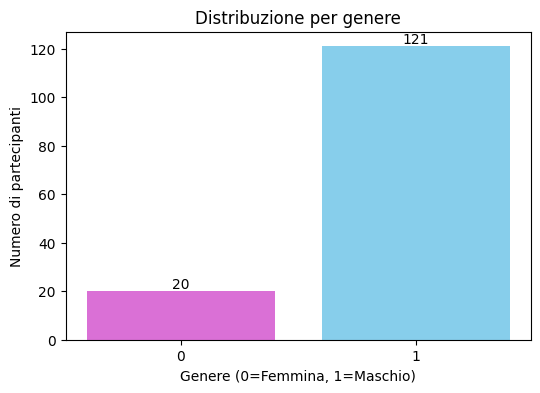

In [168]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

# Aggiungi il numero sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


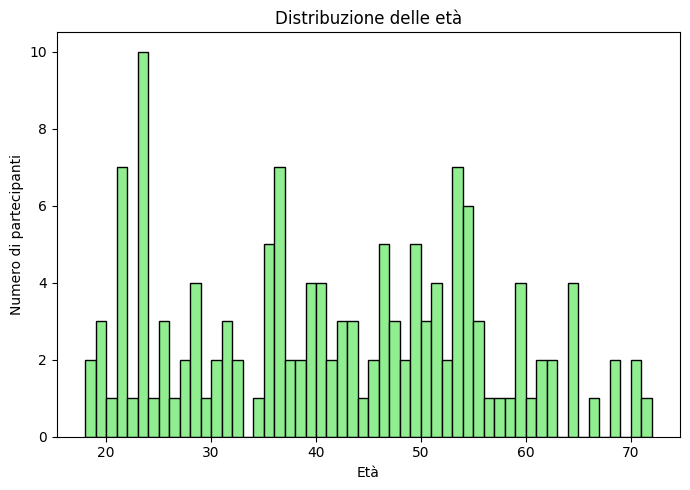

In [169]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max() + 2), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()



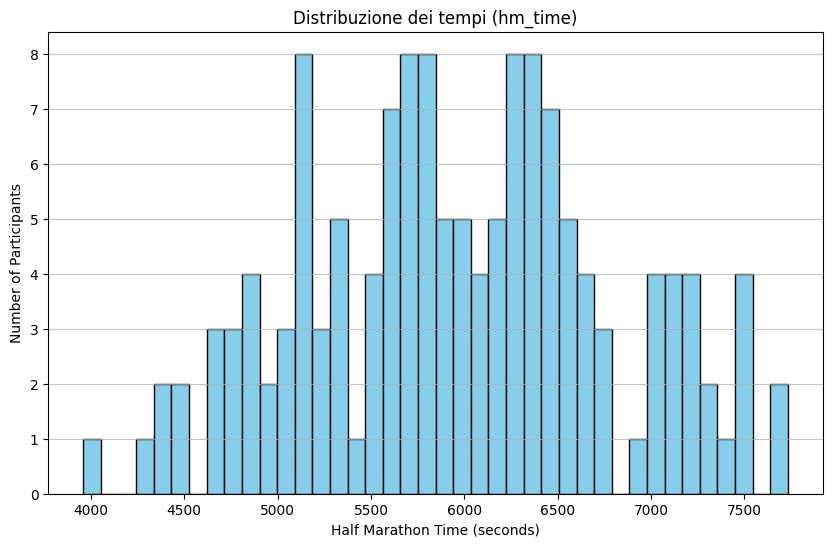

In [170]:
hm_time_sec = df['hm_time_sec']
plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (seconds)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [171]:
df.hm_time_min.mean(), df.hm_time_min.std()

(np.float64(99.50047281323876), np.float64(13.691518047372158))

Deviazione standard alta, fa intuire che sono state ricevute risposte da runner esperti e da amatori

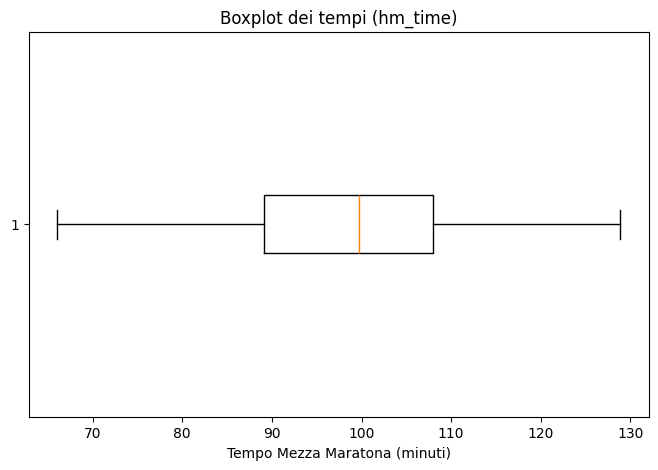

In [172]:
plt.figure(figsize=(8, 5))
plt.boxplot(df.hm_time_min, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time)')
plt.show()

Infatti qui possiamo notare gli outlier che alzano la deviazione standard

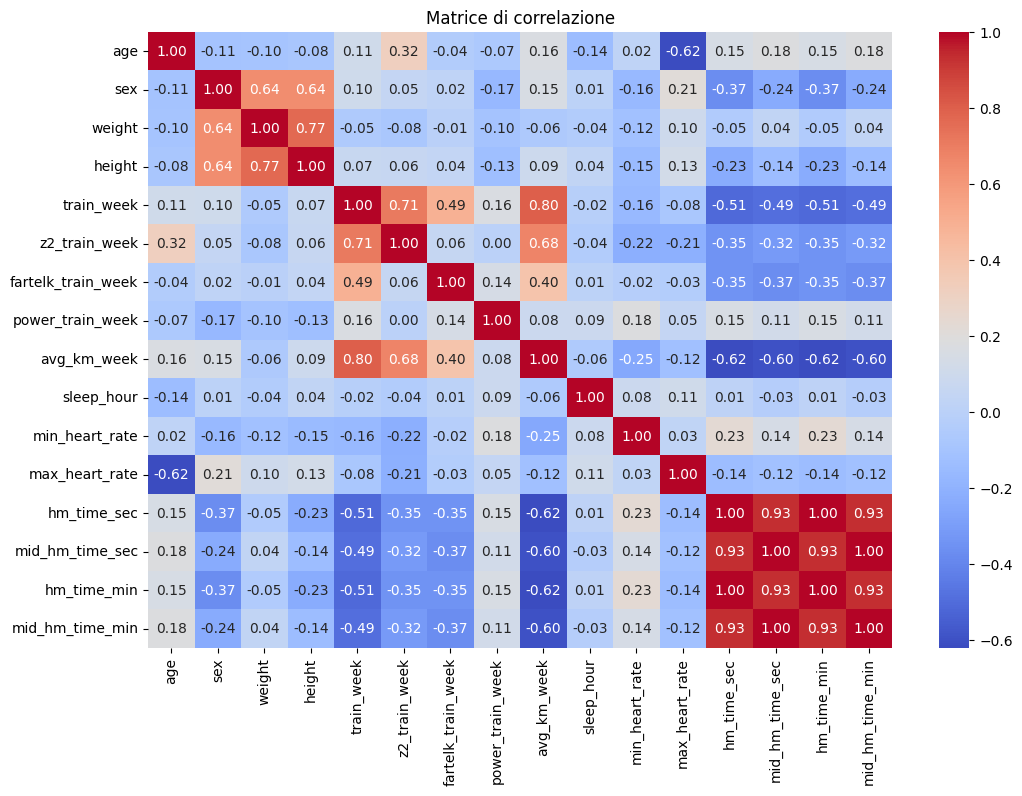

In [173]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True)
plt.title("Matrice di correlazione")
plt.show()


### Z2 vs Power

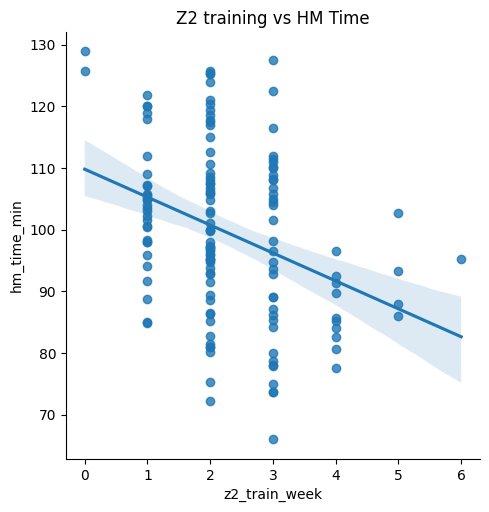

In [174]:
# Scatter plot + regressione
sns.lmplot(data=df, x='z2_train_week', y='hm_time_min')
plt.title("Z2 training vs HM Time")
plt.show()

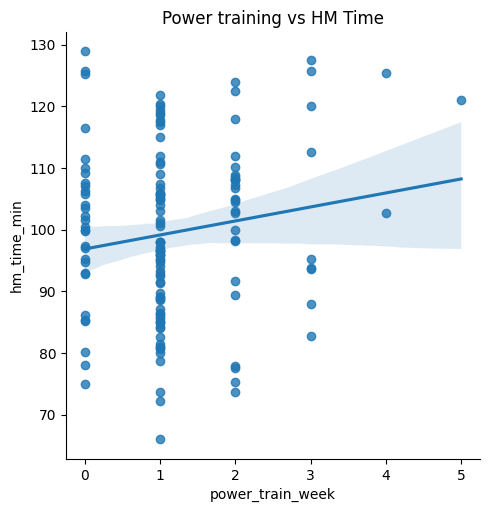

In [175]:
sns.lmplot(data=df, x='power_train_week', y='hm_time_min')
plt.title("Power training vs HM Time")
plt.show()

In [176]:
from scipy.stats import pearsonr

# Correlazioni Pearson
r_z2, _ = pearsonr(df['z2_train_week'], df['hm_time_min'])
r_power, _ = pearsonr(df['power_train_week'], df['hm_time_min'])

print(f"Correlazione Z2-HM Time: {r_z2:.2f}")
print(f"Correlazione Power-HM Time: {r_power:.2f}")

Correlazione Z2-HM Time: -0.35
Correlazione Power-HM Time: 0.15


Z2: La correlazione negativa indica che più allenamenti in zona 2 (Z2) sono associati a tempi finali migliori (più bassi). Il valore -0.303 è una correlazione debole-moderata, ma significativa a livello interpretativo: l'effetto c'è.

Power: La correlazione quasi nulla (0.15) significa che gli allenamenti di potenza non hanno un’associazione chiara con il tempo finale.

In [177]:
r_power10k, _ = pearsonr(df['power_train_week'], df['mid_hm_time_min'])
print(f"Correlazione Power vs Tempo 10km: {r_power10k:.2f}")

Correlazione Power vs Tempo 10km: 0.11


### Ore di sonno

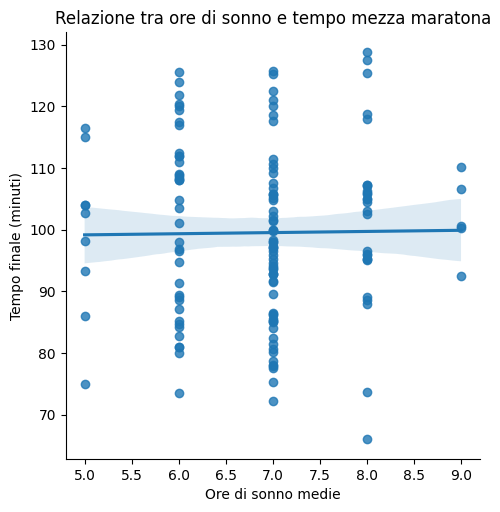

Coefficiente di correlazione: 0.012455120429674218


In [178]:
sns.lmplot(x='sleep_hour', y='hm_time_min', data=df)
plt.title('Relazione tra ore di sonno e tempo mezza maratona')
plt.xlabel('Ore di sonno medie')
plt.ylabel('Tempo finale (minuti)')
plt.show()

corr = df['sleep_hour'].corr(df['hm_time_min'])
print(f"Coefficiente di correlazione: {corr}")

Non c'è nessuna relazione diretta forte tra il sonno dell'atleta e il suo tempo finale in gara. 
Atleti con lo stesso sonno ottengono tempi molto diversi.

### KDE - Density Plot (Group By Sex)

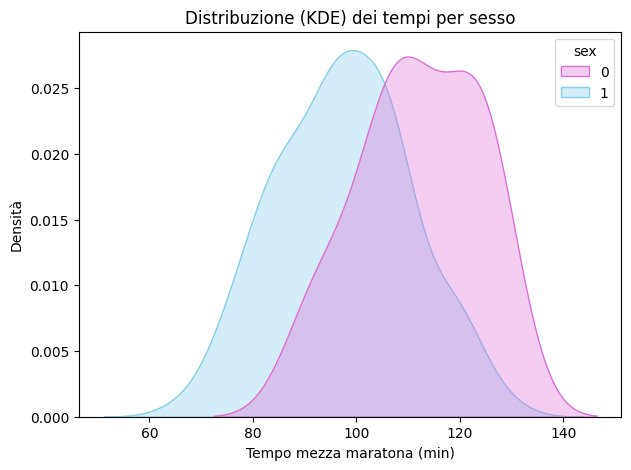

In [179]:
plt.figure(figsize=(7,5))
sns.kdeplot(
    data=df, x='hm_time_min', hue='sex',
    common_norm=False, fill=True, alpha=0.35,
    palette=['orchid', 'skyblue']
)
plt.title('Distribuzione (KDE) dei tempi per sesso')
plt.xlabel('Tempo mezza maratona (min)')
plt.ylabel('Densità')
plt.show()

###  Analisi per quartili

In [180]:
q1 = df['hm_time_min'].quantile(0.25)
q3 = df['hm_time_min'].quantile(0.75)

# Creazione gruppi
df['quartile_group'] = pd.cut(
    df['hm_time_min'],
    bins=[df['hm_time_min'].min()-0.1, q1, q3, df['hm_time_min'].max()+0.1],
    labels=['Q1', 'Q2-Q3', 'Q4']
)

In [181]:
q1_df = df[df['quartile_group'] == 'Q1']
q4_df = df[df['quartile_group'] == 'Q4']

In [182]:
print("Q1 - Media Tempo Finale:", q1_df.hm_time_min.mean())
print("Q4 - Media Tempo Finale:", q4_df.hm_time_min.mean())

Q1 - Media Tempo Finale: 81.99907407407407
Q4 - Media Tempo Finale: 117.13809523809523


In [183]:
print("Q1 - Media km settimanali:", q1_df.avg_km_week.mean())
print("Q4 - Media km settimanali:", q4_df.avg_km_week.mean())


Q1 - Media km settimanali: 59.861111111111114
Q4 - Media km settimanali: 31.285714285714285


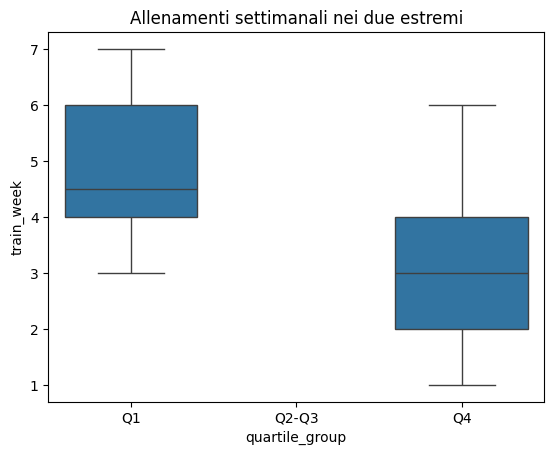

In [186]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='train_week')
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

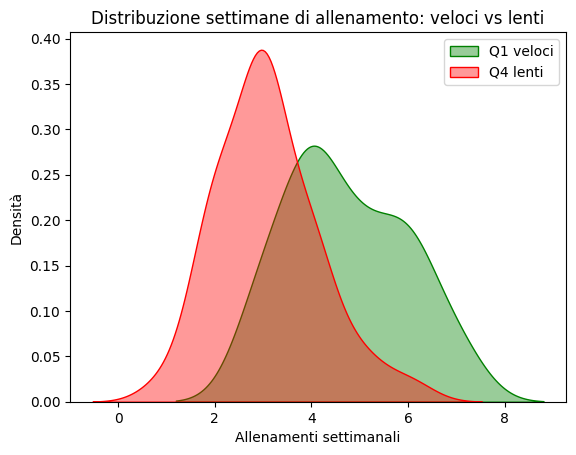

In [187]:
sns.kdeplot(data=q1_df, x='train_week', label='Q1 veloci', fill=True, alpha=0.4, color='green')
sns.kdeplot(data=q4_df, x='train_week', label='Q4 lenti', fill=True, alpha=0.4, color='red')

plt.title('Distribuzione settimane di allenamento: veloci vs lenti')
plt.xlabel('Allenamenti settimanali')
plt.ylabel('Densità')
plt.legend()
plt.show()

---

# Prevision